# Trois machines sur bus infini

Trois machines synchrones de 150 MVA, chacune derriere son transformateur
20/230 kV, alimentent un bus de charge (300 MW) relie a un **bus infini** par
deux lignes paralleles. Utile pour observer les modes intra-centrale (machines
entre elles) et le mode local de l'ensemble contre le reseau.

```
  SM1 --T1--\
  SM2 --T2--- bus 4 (charge) ===2 lignes=== bus 5 (bus infini, slack)
  SM3 --T3--/
```

Base systeme : **100 MVA, 60 Hz**.

Equivalent MATLAB : `matlab/G2Elin_V2/reseaux_test/reseaux_classiques/ThreeMachineInfiniteBus.m`.

### Comment comparer avec MATLAB

| Notebook (Python) | MATLAB |
|---|---|
| `net.run_loadflow()` | `net.Load_flow(Y_DER, false)` |
| `net.build_state_space()` | `net.buildGlobalModel()` |
| tableau modal ci-dessous | `displayModalAnalysis()` (`EigenVal_Table = 1`) |

Le tableau modal reprend les conventions MATLAB : participation
`p_ki = |v_gauche . v_droit|` normalisee par mode, `f_undamp = |lambda|/2pi`,
`f_damp = |Im(lambda)|/2pi`, `zeta = -Re(lambda)/|lambda|`, tri par
`Re(lambda)` decroissant, tous les modes conjugues inclus.

In [1]:
import sys
import pathlib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
import plotly.graph_objects as go


# Le paquet g2egrid est a la racine du projet (dossier parent de reseaux_test/).
ROOT = pathlib.Path.cwd()
ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from g2egrid import Network  # noqa: E402
from g2egrid.elements import (  # noqa: E402
    GFL1,
    GFL2,
    GFM1,
    GFM2,
    GFM3,
    GFM4,
    IB,
    Bus,
    ILoad,
    Line,
    PLoad,
    RLLoad,
    SynchronousMachine,
    SynchronousMachineTR,
    Transformer,
)

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

## 1. Construction du reseau

### 1.1 Donnees et assemblage

In [2]:
NOM_RESEAU = "ThreeMachineIB"
F_ZOOM = 5.0

f0 = 60.0
Sb = 100e6

# BusType : 1 = slack, 2 = PV, 3 = PQ

Y_DER = [ # [BusID, BusType, V_base, V_pu, Theta_rad,   Pg_W, Qg_var,     Pl_W,   Ql_var]
        (1, 2,  20e3, 1.030, 0, 120e6, 0,     0,    0),
        (2, 2,  20e3, 1.025, 0, 120e6, 0,     0,    0),
        (3, 2,  20e3, 1.020, 0, 120e6, 0,     0,    0),
        (4, 3, 230e3, 1.000, 0,     0, 0, 300e6, 60e6),
        (5, 1, 230e3, 1.000, 0,     0, 0,     0,    0),
]

# T_Lines_SI : [ID, From, To, Length_km, R_ohm/km, X_ohm/km, B_S/km]
T_Lines_SI = []

# T_Lines_pu : [ID, From, To, Length_km, R_pu, X_pu, B_pu, Un_V, Sb_VA]
#   R_pu, X_pu, B_pu : valeurs TOTALES de la ligne, en pu sur (Un_V, Sb_VA)
T_Lines_pu = [
    (1, 4, 5, 1, 0.004, 0.040, 0.04, 230e3, 100e6),
    (2, 4, 5, 1, 0.004, 0.040, 0.04, 230e3, 100e6),
]

# T_Shunts : [ID, BusID, B_pu]   (compensation shunt propre au bus)
T_Shunts = []

# T_Transfos : [ID, From, To, Sn_VA, U1_V, U2_V, R_pu, X_pu]
#   R_pu, X_pu en pu sur (Sn_VA, U1_V), ramenes a la base systeme a l'assemblage
T_Transfos = [
    (1, 1, 4, 150e6, 20e3, 230e3, 0, 0.12),
    (2, 2, 4, 150e6, 20e3, 230e3, 0, 0.12),
    (3, 3, 4, 150e6, 20e3, 230e3, 0, 0.12),
]

# T_IBs : [ID, BusID, Sn_VA, E_pu, theta_deg, R_pu, X_pu]
T_IBs = [
    (1, 5, 10000e6, 1.00, 0, 0.001, 0.01),
]

# T_SMs : [ID, BusID, Sn_VA]  ou  [ID, BusID, Sn_VA, Rt_pu, Xt_pu]
T_SMs = [
    (1, 1, 150e6),
    (2, 2, 150e6),
    (3, 3, 150e6),
]
SM_PARAMS = {}

# T_GFM1s a T_GFM4s : [ID, BusID, Sn_VA, Vdc_V]  ou  [ID, BusID, Sn_VA, Vdc_V, Rt_pu, Xt_pu]
T_GFM1s = []
T_GFM2s = []
T_GFM3s = []
T_GFM4s = []

# T_GFL1s, T_GFL2s : [ID, BusID, Sn_VA, Vdc_V]  ou  [ID, BusID, Sn_VA, Vdc_V, Rt_pu, Xt_pu]
T_GFL1s = []
T_GFL2s = []

# T_Loads : [ID, BusID, P_W, Q_var, Type]   (charges SPECIALES)
#   Type : 'I' = courant constant, 'P' = puissance constante. Les charges
#   classiques (R-L) viennent des colonnes Pl_W, Ql_var de Y_DER ; une charge
#   speciale s'y ajoute, load flow compris. Exemple : (1, 7, 0.5e6, 0.1e6, 'P'),
T_Loads = []

In [3]:
# --- bases de tension par bus, lues dans Y_DER ---
UN = {int(r[0]): r[2] for r in Y_DER}

# --- capacite shunt de chaque bus : moitie de la charge des lignes qui y
#     aboutissent (schema en pi), comme C_half = B_pu/2 dans Network.m. Un bus
#     qui n'en recoit aucune devient un noeud ALGEBRIQUE a resistance de
#     causalite R = 100 pu (Node.m / setResistor(100)). ---
Cbus = {int(r[0]): 0.0 for r in Y_DER}
for _id, i, j, km, _r, _x, b_km in T_Lines_SI:
    b_pu = b_km * km * (UN[i] ** 2 / Sb)
    Cbus[i] += b_pu / 2.0
    Cbus[j] += b_pu / 2.0
for _id, i, j, _km, _r, _x, b_pu, Un, Sb_l in T_Lines_pu:
    b_pu = b_pu * (UN[i] ** 2 / Sb) / (Un ** 2 / Sb_l)  # base de la ligne -> base systeme
    Cbus[i] += b_pu / 2.0
    Cbus[j] += b_pu / 2.0
# compensation shunt propre a un bus (banc de condensateurs), qui s'ajoute a
# la charge capacitive des lignes. MATLAB n'a pas de colonne pour cela dans
# Y_DER : d'ou une table a part, plutot qu'une colonne en plus.
for _id, b, B_pu in T_Shunts:
    Cbus[b] += B_pu

# --- charges speciales de T_Loads : leur consommation s'ajoute a celle de
#     Y_DER dans le load flow ---
CHARGES_SPECIALES = {"I": ILoad, "P": PLoad}
S_spec = {int(r[0]): [0.0, 0.0] for r in Y_DER}
for _id, b, P, Q, typ in T_Loads:
    if typ not in CHARGES_SPECIALES:
        raise ValueError(f"T_Loads, charge {_id} : type '{typ}' inconnu ('I' ou 'P')")
    S_spec[b][0] += P
    S_spec[b][1] += Q

# --- assemblage du reseau
net = Network(f0=f0, Sb=Sb)

for bid, btype, Un, Vpu, theta, Pg, Qg, Pl, Ql in Y_DER:  # Y_DER
    net.add(
        Bus(
            int(bid),
            Un,
            btype=int(btype),
            V=Vpu,
            theta=theta,
            Pg=Pg,
            Qg=Qg,
            Pl=Pl + S_spec[int(bid)][0],
            Ql=Ql + S_spec[int(bid)][1],
            C=Cbus[int(bid)],
        )
    )

for lid, i, j, km, r_km, x_km, _b in T_Lines_SI:  # T_Lines_SI
    ZB = UN[i] ** 2 / Sb
    net.add(
        Line(
            f"L{int(lid)}_{i}_{j}", i, j, R=r_km * km / ZB, X=x_km * km / ZB, wb=net.wb
        )
    )

for lid, i, j, _km, r_pu, x_pu, _b, Un, Sb_l in T_Lines_pu:  # T_Lines_pu
    k = (Un ** 2 / Sb_l) / (UN[i] ** 2 / Sb)  # base de la ligne -> base systeme
    net.add(Line(f"L{int(lid)}_{i}_{j}", i, j, R=r_pu * k, X=x_pu * k, wb=net.wb))

# Une prise hors nominal se declare par U1_V/U2_V, comme dans Network.m :
# n = (U1/U2)/(Un_i/Un_j), egal a 1 quand U1, U2 sont les tensions des bus.
for tid, i, j, Sn, U1, U2, R, X in T_Transfos:  # T_Transfos
    k = (Sb / Sn) * (U1 / UN[i]) ** 2  # base du transfo -> base systeme
    n = (U1 / U2) / (UN[i] / UN[j])
    net.add(Transformer(f"T{int(tid)}_{i}_{j}", i, j, R=R * k, X=X * k, wb=net.wb, n=n))

for _id, b, Sn, _E, _th, R, X in T_IBs:  # T_IBs
    net.add(IB(f"IB{b}", b, R=R, X=X, wb=net.wb, Sn=Sn, Sb=Sb))

# Colonnes optionnelles Rt_pu, Xt_pu des tables de DER : transfo de
# raccordement INTEGRE a l'equipement. Sans elles, la machine n'a pas de
# transfo (a declarer dans T_Transfos) et le convertisseur garde son filtre
# R2/L2 par defaut.
for _id, b, Sn, *Tr in T_SMs:  # T_SMs
    if Tr:
        net.add(SynchronousMachineTR(f"SM{b}", b, Sn=Sn, Sb=Sb, wb=net.wb, Rt=Tr[0], Lt=Tr[1], **SM_PARAMS))
    else:
        net.add(SynchronousMachine(f"SM{b}", b, Sn=Sn, Sb=Sb, wb=net.wb, **SM_PARAMS))

for T_GFM, GFM in ((T_GFM1s, GFM1), (T_GFM2s, GFM2), (T_GFM3s, GFM3), (T_GFM4s, GFM4)):  # T_GFM1s a T_GFM4s
    for _id, b, Sn, _Vdc, *Tr in T_GFM:
        tr = dict(R2_pu=Tr[0], L2_pu=Tr[1]) if Tr else {}
        net.add(GFM(f"GFM{b}", b, Sn=Sn, Sb=Sb, wb=net.wb, **(GFM_PARAMS | tr)))

for T_GFL, GFL in ((T_GFL1s, GFL1), (T_GFL2s, GFL2)):  # T_GFL1s, T_GFL2s
    for _id, b, Sn, _Vdc, *Tr in T_GFL:
        tr = dict(R2_pu=Tr[0], L2_pu=Tr[1]) if Tr else {}
        net.add(GFL(f"GFL{b}", b, Sn=Sn, Sb=Sb, wb=net.wb, **(GFL_PARAMS | tr)))

# Charges classiques : colonnes Pl_W, Ql_var de Y_DER -> charge R-L a
# impedance constante (GenericLoad.m). Une inductance ne peut pas consommer
# un reactif negatif ou nul : condensateur dans T_Shunts, ou charge speciale.
n_rl = 0
for bid, *_, Pl, Ql in Y_DER:  # Y_DER : charges classiques
    if Pl == 0 and Ql == 0:
        continue
    if Ql <= 0:
        raise ValueError(
            f"bus {int(bid)} : Ql = {Ql:g} var. Une charge R-L demande Ql > 0 ; "
            "declarer le condensateur dans T_Shunts ou la charge dans T_Loads ('P' ou 'I')"
        )
    net.add(RLLoad(f"Load{int(bid)}", int(bid), P=Pl / Sb, Q=Ql / Sb, wb=net.wb))
    n_rl += 1

for lid, b, P, Q, typ in T_Loads:  # T_Loads : charges speciales
    net.add(CHARGES_SPECIALES[typ](f"Load{typ}{int(lid)}_{b}", b, P=P / Sb, Q=Q / Sb))

n_gfm = len(T_GFM1s) + len(T_GFM2s) + len(T_GFM3s) + len(T_GFM4s)
print(
    f"{NOM_RESEAU} : {len(Y_DER)} bus, "
    f"{len(T_Lines_SI) + len(T_Lines_pu)} ligne(s), {len(T_Transfos)} transfo(s), "
    f"{len(T_IBs)} bus infini, {len(T_SMs)} machine(s), {n_gfm} GFM, "
    f"{len(T_GFL1s) + len(T_GFL2s)} GFL, {n_rl} charge(s) R-L, "
    f"{len(T_Loads)} charge(s) speciale(s)"
)

ThreeMachineIB : 5 bus, 2 ligne(s), 3 transfo(s), 1 bus infini, 3 machine(s), 0 GFM, 0 GFL, 1 charge(s) R-L, 0 charge(s) speciale(s)


### 1.2 Load flow

In [4]:
lf = net.run_loadflow()
print(
    f"Load flow : converge en {lf.iterations} iterations (mismatch {lf.mismatch:.2e})\n"
)

print(
    f"{'bus':>4} {'|V| [pu]':>10} {'angle [deg]':>12} "
    f"{'P inj [pu]':>12} {'Q inj [pu]':>12}"
)
print("-" * 54)
for b, i in net._bus_index().items():
    print(
        f"{b:>4} {abs(lf.V[i]):>10.4f} {np.degrees(np.angle(lf.V[i])):>12.4f} "
        f"{lf.S[i].real:>12.4f} {lf.S[i].imag:>12.4f}"
    )
print(
    f"\nSomme des injections : P = {lf.S.real.sum():+.4f} pu, "
    f"Q = {lf.S.imag.sum():+.4f} pu  (= pertes)"
)

Load flow : converge en 5 iterations (mismatch 1.73e-14)

 bus   |V| [pu]  angle [deg]   P inj [pu]   Q inj [pu]
------------------------------------------------------
   1     1.0300       5.9223       1.2000       0.4017
   2     1.0250       5.9487       1.2000       0.3362
   3     1.0200       5.9752       1.2000       0.2714
   4     1.0031       0.6380      -3.0000      -0.6000
   5     1.0000       0.0000      -0.5678      -0.1333

Somme des injections : P = +0.0322 pu, Q = +0.2760 pu  (= pertes)


## 2. Modele d'etat

Equilibre element par element (Newton sur `[f; g] = 0`), puis assemblage
global : cablage des ports par LFT, elimination des variables algebriques
par complement de Schur.

In [5]:
net.solve_equilibrium()
ss = net.build_state_space()

print(ss)
print(f"\n{len(ss.states)} etats, {len(ss.inputs)} entrees, {len(ss.outputs)} sorties")
print(f"stable : {ss.is_stable()}   max Re(lambda) = {ss.eig().real.max():+.4e}")

print("\nEtats par element :")
seen = []
for s in ss.states:
    owner = s.split(".")[0]
    if owner not in seen:
        seen.append(owner)
for owner in seen:
    noms = [s.split(".", 1)[1] for s in ss.states if s.startswith(owner + ".")]
    print(f"  {owner:<12} {len(noms):>3} : {', '.join(noms)}")

<StateSpace 72 etats, 12 entrees, 62 sorties | max Re(lambda)=+0.000e+00>

72 etats, 12 entrees, 62 sorties
stable : True   max Re(lambda) = +0.0000e+00

Etats par element :
  bus4           2 : vd, vq
  bus5           2 : vd, vq
  L1_4_5         2 : i_d, i_q
  L2_4_5         2 : i_d, i_q
  T1_1_4         2 : i_d, i_q
  T2_2_4         2 : i_d, i_q
  T3_3_4         2 : i_d, i_q
  IB5            3 : i_d, i_q, theta
  SM1           17 : phi_d, phi_q, phi_fd, phi_1d, phi_1q, phi_2q, Dwr, Pm, Dw1, v1, v2, vpss, e1, e2, efd, e3, theta
  SM2           17 : phi_d, phi_q, phi_fd, phi_1d, phi_1q, phi_2q, Dwr, Pm, Dw1, v1, v2, vpss, e1, e2, efd, e3, theta
  SM3           17 : phi_d, phi_q, phi_fd, phi_1d, phi_1q, phi_2q, Dwr, Pm, Dw1, v1, v2, vpss, e1, e2, efd, e3, theta
  Load4          4 : i_d, i_q, dp_f, dq_f


### 2.1 Tableau modal

Une ligne par valeur propre, triee par partie reelle decroissante (modes les
plus lents d'abord), comme `displayModalAnalysis` en MATLAB : une paire
conjuguee occupe deux lignes. L'index `Mode` est l'indice `k` de `lam[k]`.

| Colonne | Definition |
|---|---|
| `Re`, `Im` | parties reelle [1/s] et imaginaire [rad/s] de la valeur propre |
| `f_und [Hz]` | frequence propre non amortie, `abs(lambda) / 2pi` |
| `f_dam [Hz]` | frequence d'oscillation, `abs(Im) / 2pi` |
| `zeta [%]` | amortissement, `-Re / abs(lambda)` |
| `Etat j`, `%j` | j-ieme etat le plus participant et sa participation `abs(v_ki . w_ik)`, normalisee a 100 % par mode |

In [6]:
lam, Vr = np.linalg.eig(ss.A)
Wl = np.linalg.inv(Vr)
Pf = np.abs(Vr.T) * np.abs(Wl)  # Pf[k, i] : participation de l'etat i au mode k
Pf = Pf / np.maximum(Pf.sum(axis=1, keepdims=True), 1e-30)
top3 = np.argsort(-Pf, axis=1)[:, :3]  # les trois etats les plus participants
k = np.arange(len(lam))

mag = np.abs(lam)
zeta = np.where(mag > 1e-10, -lam.real / np.where(mag > 1e-10, mag, 1.0), 0.0)

T_eig = pd.DataFrame(
    {
        "Re": lam.real,
        "Im": lam.imag,
        "f_und [Hz]": mag / (2 * np.pi),
        "f_dam [Hz]": np.abs(lam.imag) / (2 * np.pi),
        "zeta [%]": 100 * zeta,
    }
)
for j in range(3):
    T_eig[f"Etat {j + 1}"] = [ss.states[i] for i in top3[:, j]]
    T_eig[f"%{j + 1}"] = 100 * Pf[k, top3[:, j]]
T_eig = T_eig.iloc[np.argsort(-lam.real, kind="stable")]
T_eig.index.name = "Mode"



T_eig

,Re,Im,f_und [Hz],f_dam [Hz],zeta [%],Etat 1,%1,Etat 2,%2,Etat 3,%3
Mode,,,,,,,,,,,
69,0.000000,0.0,0.000000,0.0,0.0,IB5.theta,100.000000,bus4.vd,0.000000,bus5.vd,0.000000
66,-0.187372,0.0,0.029821,0.0,100.0,SM1.vpss,40.010260,SM2.vpss,30.851182,SM3.vpss,24.628542
67,-0.188450,0.0,0.029993,0.0,100.0,SM1.vpss,50.724538,SM2.vpss,37.884326,SM3.vpss,4.790395
68,-0.188657,0.0,0.030026,0.0,100.0,SM3.vpss,64.247684,SM2.vpss,25.233084,SM1.vpss,3.526477
63,-0.531683,0.0,0.084620,0.0,100.0,SM1.v1,29.214293,SM2.v1,22.724754,SM3.v1,18.398750
...,...,...,...,...,...,...,...,...,...,...,...
8,-278997.726063,0.0,44403.867214,0.0,100.0,T3_3_4.i_q,21.498002,T1_1_4.i_q,18.738771,SM3.phi_q,16.502290
9,-278997.934174,0.0,44403.900336,0.0,100.0,T2_2_4.i_q,26.765098,SM2.phi_q,21.626686,T2_2_4.i_d,18.185289
4,-286522.958003,0.0,45601.545075,0.0,100.0,T3_3_4.i_d,13.684281,T2_2_4.i_d,13.002363,T1_1_4.i_d,12.322603


### 2.2 Carte des valeurs propres

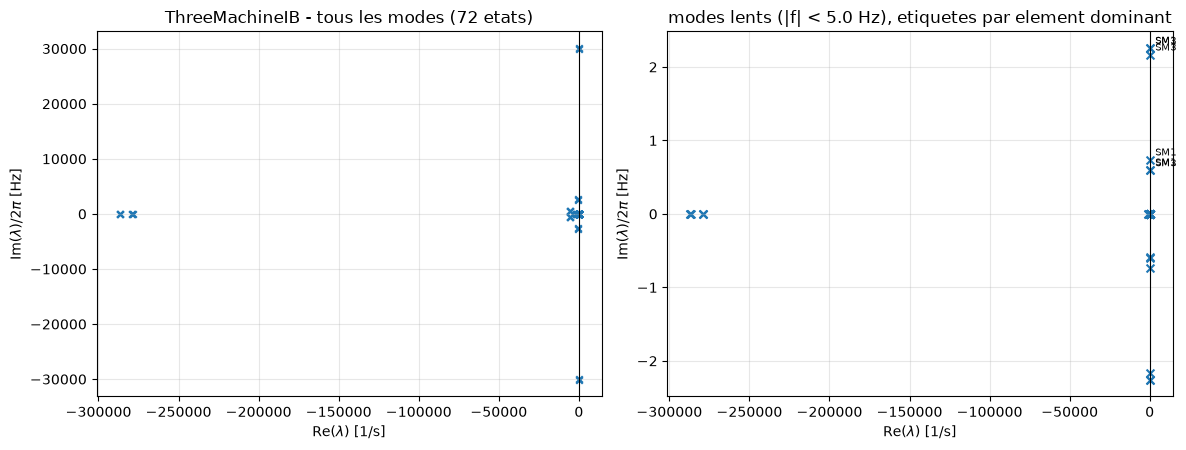

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))

ax[0].scatter(lam.real, lam.imag / (2 * np.pi), s=22, marker="x")
ax[0].axvline(0.0, color="k", lw=0.8)
ax[0].set_xlabel("Re($\\lambda$) [1/s]")
ax[0].set_ylabel("Im($\\lambda$)/2$\\pi$ [Hz]")
ax[0].set_title(f"{NOM_RESEAU} - tous les modes ({len(lam)} etats)")
ax[0].grid(True, alpha=0.3)

zoom = np.abs(lam.imag) / (2 * np.pi) <= F_ZOOM
ax[1].scatter(lam[zoom].real, lam[zoom].imag / (2 * np.pi), s=32, marker="x")
for k in np.flatnonzero(zoom & (lam.imag > 1e-6)):
    ax[1].annotate(
        ss.states[top3[k, 0]].split(".")[0],
        (lam[k].real, lam[k].imag / (2 * np.pi)),
        fontsize=7,
        xytext=(4, 3),
        textcoords="offset points",
    )
ax[1].axvline(0.0, color="k", lw=0.8)
ax[1].set_xlabel("Re($\\lambda$) [1/s]")
ax[1].set_ylabel("Im($\\lambda$)/2$\\pi$ [Hz]")
ax[1].set_title(f"modes lents (|f| < {F_ZOOM} Hz), etiquetes par element dominant")
ax[1].grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

In [8]:
fig = go.Figure()

fig.add_trace(go.Scatter(x=T_eig["Re"], y=T_eig["Im"], mode="markers"))

fig.update_xaxes(range=[-1000, 10])
fig.update_yaxes(range=[-10, 1000])
fig.show()